## **Machine Learning at scale practicals**

## **Practical 1**

### **1. Download the dataset**

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
from numba import njit, prange

### **2. Data Download and extraction**

In [2]:
URL = "https://files.grouplens.org/datasets/movielens/ml-32m.zip"
ZIP_FILE = "ml-32m.zip"
EXTRACT_FOLDER = "ml-32m"
RATINGS_PATH = "ml-32m/ml-32m/ratings.csv"

print(f"Downloading {URL}...")
!wget -q {URL}

if os.path.exists(ZIP_FILE):
    print(f"Extracting {ZIP_FILE}...")
    !unzip -q -o {ZIP_FILE} -d {EXTRACT_FOLDER}
    print("Extraction complete.\n")
else:
    raise FileNotFoundError(f"Download failed: {ZIP_FILE} not found")

Extracting ml-32m.zip...
Extraction complete.



### **3. Build Indices**
Create bidirectional indices for (a) users and (b) movies


In [3]:
# Load data from csv to numpy
print("Loading ratings data...")
ratings = np.loadtxt(RATINGS_PATH, delimiter=",", skiprows=1, usecols=(0, 1, 2))

user_ids = ratings[:, 0].astype(int)
movie_ids = ratings[:, 1].astype(int)
rating_values = ratings[:, 2]

print(f"Loaded {len(ratings):,} ratings\n")

Loading ratings data...
Loaded 32,000,204 ratings



In [4]:
# Creating a bidirectional indices for (a) users and (b) movies
print("Building index structures...")

# Initialize data structures
userid_to_idx = {}
idx_to_userid = []
data_by_user = []

movieid_to_idx = {}
idx_to_movieid = []
data_by_movie = []

# Build indices by iterating through all ratings
for user_id, movie_id, rating in ratings:
    user_id = int(user_id)
    movie_id = int(movie_id)

    # Add user if not seen before
    if user_id not in userid_to_idx:
        userid_to_idx[user_id] = len(idx_to_userid)
        idx_to_userid.append(user_id)
        data_by_user.append([])

    # Add movie if not seen before
    if movie_id not in movieid_to_idx:
        movieid_to_idx[movie_id] = len(idx_to_movieid)
        idx_to_movieid.append(movie_id)
        data_by_movie.append([])

    # Store rating in both indices
    user_idx = userid_to_idx[user_id]
    movie_idx = movieid_to_idx[movie_id]

    data_by_user[user_idx].append((movie_idx, rating))
    data_by_movie[movie_idx].append((user_idx, rating))

print(f"Indexed {len(idx_to_userid):,} users and {len(idx_to_movieid):,} movies\n")

Building index structures...
Indexed 200,948 users and 84,432 movies



In [5]:
# Simple interfaces to query the indexed data
def get_user_rating_count(user_id):
    """Return number of movies rated by a user"""
    return len(data_by_user[userid_to_idx[user_id]])

def get_movie_rating_count(movie_id):
    """Return number of users who rated a movie"""
    return len(data_by_movie[movieid_to_idx[movie_id]])

### **4. Exploring the dataset**

**Movies Statistics**

In [6]:
# Load Movie Titles
movie_titles = {}
with open('ml-32m/ml-32m/movies.csv', encoding='utf-8') as movies:
    reader = csv.reader(movies)
    next(reader)
    for row in reader:
        movie_titles[int(row[0])] = row[1]

In [7]:
movie_stats = []
for movie_idx, ratings_list in enumerate(data_by_movie):
    count = len(ratings_list)
    if count > 0:
        total_rating = sum(r for u, r in ratings_list)
        mean_rating = total_rating / count
    else:
        mean_rating = 0

    raw_id = idx_to_movieid[movie_idx]
    title = movie_titles.get(raw_id, f"Movie {raw_id}")

    movie_stats.append({
        "title": title,
        "count": count,
        "mean": mean_rating
    })

sorted_by_popularity = sorted(movie_stats, key=lambda x: x['count'], reverse=True)
top_20 = sorted_by_popularity[:10]

top_titles = [m['title'] for m in top_20]
top_counts = [m['count'] for m in top_20]

item_means = [m['mean'] for m in movie_stats if m['count'] > 0]

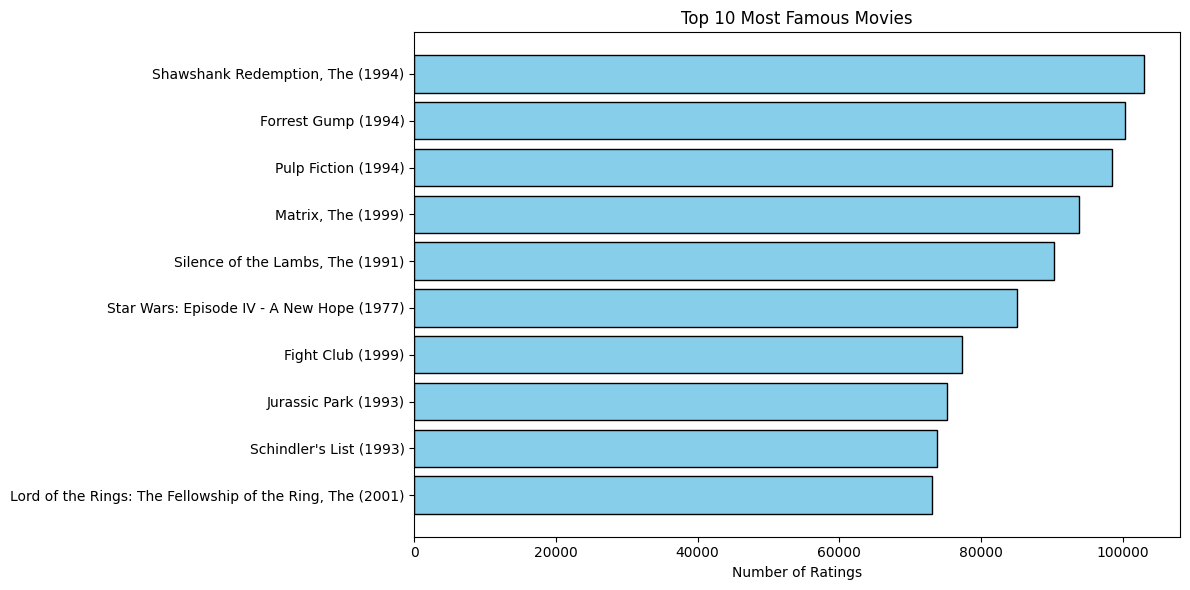

In [8]:
# Top 10 Most Famous Movies
plt.figure(figsize=(12, 6))
y_pos = np.arange(len(top_titles))
plt.barh(y_pos, top_counts, align='center', color='skyblue', edgecolor='black')
plt.yticks(y_pos, top_titles)
plt.gca().invert_yaxis()
plt.xlabel('Number of Ratings')
plt.title('Top 10 Most Famous Movies')
plt.savefig('most_famous_movies.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

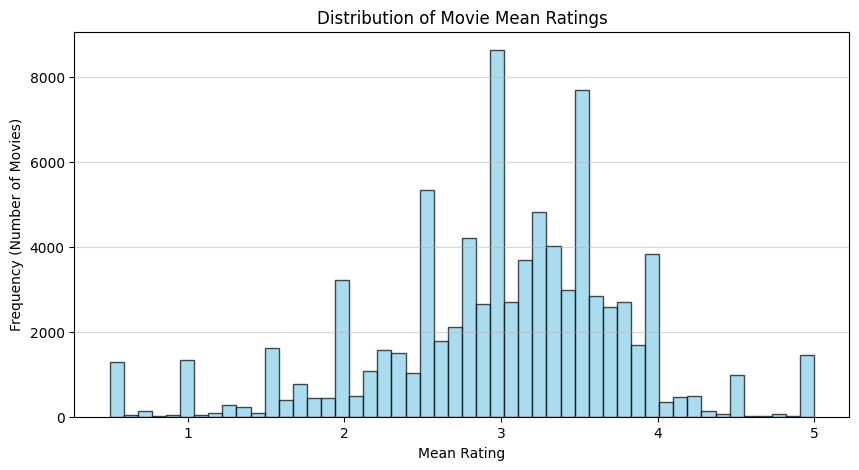

In [9]:
# Distribution of Item Mean Ratings
plt.figure(figsize=(10, 5))
plt.hist(item_means, bins=50, color='skyblue', alpha=0.7, edgecolor='black')
plt.title('Distribution of Movie Mean Ratings')
plt.xlabel('Mean Rating')
plt.ylabel('Frequency (Number of Movies)')
plt.grid(axis='y', alpha=0.5)
plt.savefig('movie_mean_ratings.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

**User Statistics**

In [10]:
user_means = []
for user_idx, ratings_list in enumerate(data_by_user):
    count = len(ratings_list)
    if count > 0:
        total_rating = sum(r for m, r in ratings_list)
        mean_val = total_rating / count
        user_means.append(mean_val)

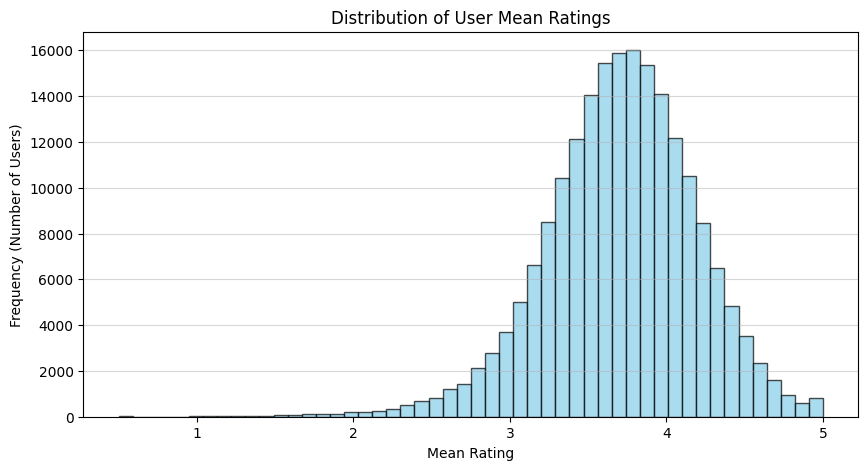

In [11]:
# Distribution of User Mean Ratings
plt.figure(figsize=(10, 5))
plt.hist(user_means, bins=50, color='skyblue', alpha=0.7, edgecolor='black')
plt.title('Distribution of User Mean Ratings')
plt.xlabel('Mean Rating')
plt.ylabel('Frequency (Number of Users)')
plt.grid(axis='y', alpha=0.5)
plt.savefig('user_mean_ratings.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

### **5. Ratings distribution analysis**

Plotting rating distribution...


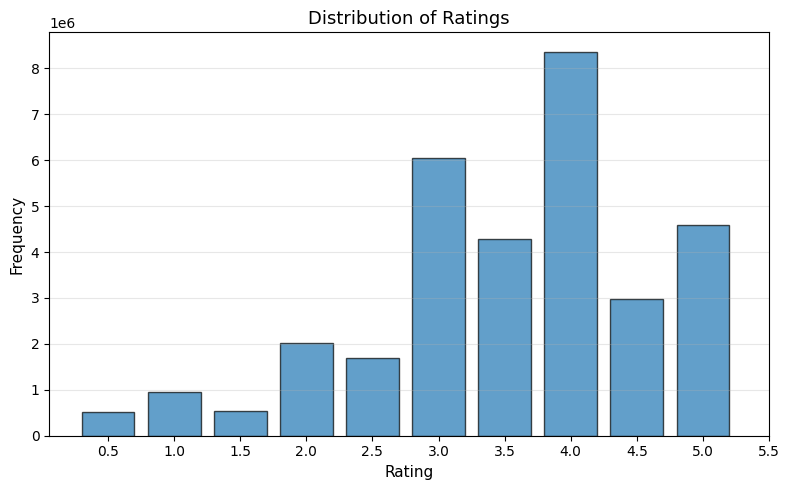

In [12]:
print("Plotting rating distribution...")

fig, ax = plt.subplots(figsize=(8, 5))
rating_bins = [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5]

ax.hist(rating_values, bins=rating_bins, edgecolor="black", rwidth=0.8, alpha=0.7, align='left')
ax.set_xlabel("Rating", fontsize=11)
ax.set_ylabel("Frequency", fontsize=11)
ax.set_title("Distribution of Ratings", fontsize=13)
ax.set_xticks(rating_bins)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('ratings_distribution.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

This user ratings show a positive skew, clustering around 3.5-4.5 stars because people tend to watch and rate movies they expect to enjoy.

The rating patterns reveal user preferences for whole numbers over half-stars,and scarcity of very low ratings since viewers often abandon disliked movies rather than rating them poorly.


### **6. Power law analysis**

Analyzing degree distributions for power law behavior...


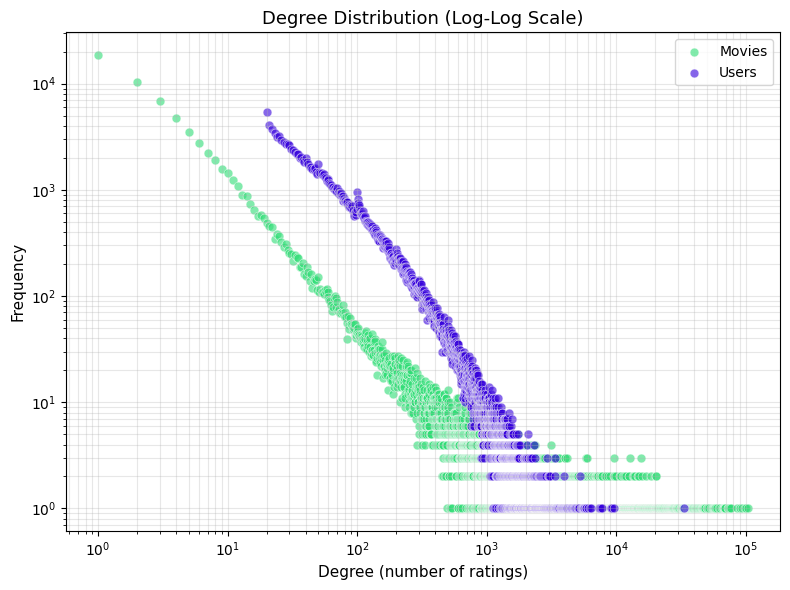

Summary statistics

User degrees - Min: 20, Max: 33,332, Mean: 159.2
Movie degrees - Min: 1, Max: 102,929, Mean: 379.0

The user degree minimum of 20 is due to dataset filtering.

This truncation affects the power law distribution shape.


In [13]:
print("Analyzing degree distributions for power law behavior...")

# Extract degree (number of ratings) for each user and movie
user_degrees = [len(ratings_list) for ratings_list in data_by_user]
movie_degrees = [len(ratings_list) for ratings_list in data_by_movie]

# Create log-log scatter plot
fig, ax = plt.subplots(figsize=(8, 6))

for degrees, color, label in [(movie_degrees, '#2edd75', 'Movies'),
                               (user_degrees, '#3500dc', 'Users')]:
    # Get unique degree values and their frequencies
    unique_degrees, counts = np.unique(degrees, return_counts=True)
    ax.scatter(unique_degrees, counts, c=color, s=40, alpha=0.6,
               label=label, edgecolors='white', linewidths=0.5)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Degree (number of ratings)', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Degree Distribution (Log-Log Scale)', fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('power_law_distribution.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Summary statistics
print("Summary statistics")
print(f"\nUser degrees - Min: {min(user_degrees)}, Max: {max(user_degrees):,}, "
      f"Mean: {np.mean(user_degrees):.1f}")
print(f"Movie degrees - Min: {min(movie_degrees)}, Max: {max(movie_degrees):,}, "
      f"Mean: {np.mean(movie_degrees):.1f}")
print("\nThe user degree minimum of 20 is due to dataset filtering.")
print("\nThis truncation affects the power law distribution shape.")


This is actually a power law distribution as it describe a pattern where a few entities have extremely high values while most have very low values, appearing as a straight line on a log-log plot.

In movie rating data, we notice a few blockbuster films receive millions of ratings while most independent films get very few, and similarly a few super-active users rates thousands of movies while most users rate only occasionally.

The MovieLens32M dataset is artificially truncated because it excludes all users who rated fewer than 20 movies, cutting off the left tail of the natural distribution.
This truncation distorts the visual pattern on log-log plots, creating a flat or broken line on the left side instead of the expected smooth power law curve.

On the other hand, the movie rating distribution appears to follow a scale-free pattern, whereas the user rating distribution deviates sligthly from this pattern.

## **Practical 2**

### **1. Download a smaller dataset**

In [35]:
# URL of the dataset
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
zip_file2 = "ml-latest-small.zip"
extract_folder2 = "ml-latest-small"

print(f"Starting download of {url}...")
!wget -q $url

print("Download complete.")
if os.path.exists(zip_file2):
    print(f"Successfully downloaded {zip_file2}.")
    print(f"Unzipping {zip_file2}...")
    !unzip -o $zip_file2 -d $extract_folder2

    print(f"Successfully unzipped to '{extract_folder2}' folder.")
    print(f"\nContents of {extract_folder2}:")
    !ls -l $extract_folder2
else:
    print(f"Error: {zip_file2} was not downloaded.")

Starting download of https://files.grouplens.org/datasets/movielens/ml-latest-small.zip...
Download complete.
Successfully downloaded ml-latest-small.zip.
Unzipping ml-latest-small.zip...
Archive:  ml-latest-small.zip
  inflating: ml-latest-small/ml-latest-small/links.csv  
  inflating: ml-latest-small/ml-latest-small/tags.csv  
  inflating: ml-latest-small/ml-latest-small/ratings.csv  
  inflating: ml-latest-small/ml-latest-small/README.txt  
  inflating: ml-latest-small/ml-latest-small/movies.csv  
Successfully unzipped to 'ml-latest-small' folder.

Contents of ml-latest-small:
total 4
drwxr-xr-x 2 root root 4096 Nov 24 15:54 ml-latest-small


### **2. Build Indices**

In [36]:
# Load data
print("Loading ratings...")
ratings = np.loadtxt(
    "ml-latest-small/ml-latest-small/ratings.csv",
    delimiter=",",
    skiprows=1,
    usecols=(0, 1, 2)
)

users = ratings[:, 0].astype(int)
movies = ratings[:, 1].astype(int)
rating = ratings[:, 2].astype(float)

print(f"Loaded {len(ratings):,} ratings")

Loading ratings...
Loaded 100,836 ratings


In [37]:
#The data structure
number_of_users = 0
userid_to_idx  = {}
idx_to_userid  = []
data_by_user   = []

number_of_movies = 0
movieid_to_idx = {}
idx_to_movieid = []
data_by_movie  = []

for row in ratings:
  if not row[0] in userid_to_idx:
    idx_to_userid.append(row[0])
    userid_to_idx[row[0]] = number_of_users
    number_of_users += 1
    data_by_user.append([])
  if not row[1] in movieid_to_idx:
    idx_to_movieid.append(row[1])
    movieid_to_idx[row[1]] = number_of_movies
    number_of_movies += 1
    data_by_movie.append([])

  data_by_user[userid_to_idx[row[0]]].append((movieid_to_idx[row[1]],row[2].item()))
  data_by_movie[movieid_to_idx[row[1]]].append((userid_to_idx[row[0]],row[2].item()))

### **3. Split dataset into train and test datasets**
Split the ratings data into training (90%) and test (10%) sets

In [38]:
def split_train_test(data_by_user, number_of_users, number_of_movies,
                     train_ratio=0.9, random_seed=42, verbose=True):
    """
    Split rating data into training and test sets
    Parameters
    data_by_user : list of lists
    number_of_users : int
    number_of_movies : int
    train_ratio : float
    random_seed : int, Random seed for reproducibility
    verbose : bool

    Returns
    tuple of (data_by_user_train, data_by_user_test,
              data_by_movie_train, data_by_movie_test)
    """

    # Input validation
    if not 0.0 < train_ratio < 1.0:
        raise ValueError(f"train_ratio must be between 0 and 1, got {train_ratio}")

    if len(data_by_user) != number_of_users:
        raise ValueError(f"data_by_user length ({len(data_by_user)}) "
                        f"doesn't match number_of_users ({number_of_users})")

    random.seed(random_seed)

    if verbose:
        print("Splitting data into train and test sets...")
        print(f"({train_ratio*100:.0f}% train, "
              f"{(1-train_ratio)*100:.0f}% test)")

    # Initialize empty structures
    data_by_user_train = [[] for _ in range(number_of_users)]
    data_by_user_test = [[] for _ in range(number_of_users)]
    data_by_movie_train = [[] for _ in range(number_of_movies)]
    data_by_movie_test = [[] for _ in range(number_of_movies)]

    # Split each user's ratings
    for user_idx in range(number_of_users):
        user_ratings = data_by_user[user_idx].copy()

        random.shuffle(user_ratings)
        split_point = int(train_ratio * len(user_ratings))

        train_ratings = user_ratings[:split_point]
        test_ratings = user_ratings[split_point:]

        data_by_user_train[user_idx] = train_ratings
        data_by_user_test[user_idx] = test_ratings

        # Populate movie-centric structures
        for movie_idx, rating in train_ratings:
            data_by_movie_train[movie_idx].append((user_idx, rating))

        for movie_idx, rating in test_ratings:
            data_by_movie_test[movie_idx].append((user_idx, rating))

    # Calculate and display statistics
    if verbose:
        # Verify split
        total_ratings = sum(len(ratings) for ratings in data_by_user)
        train_count = sum(len(ratings) for ratings in data_by_user_train)
        test_count = sum(len(ratings) for ratings in data_by_user_test)

        print(f"Total ratings: {total_ratings:,}")
        print(f"Train: {train_count:,} ({train_count/total_ratings*100:.1f}%)")
        print(f"Test: {test_count:,} ({test_count/total_ratings*100:.1f}%)\n")

    return (data_by_user_train, data_by_user_test,
            data_by_movie_train, data_by_movie_test)

In [39]:
data_by_user_train, data_by_user_test, data_by_movie_train, data_by_movie_test = \
    split_train_test(data_by_user, number_of_users, number_of_movies)

Splitting data into train and test sets...
(90% train, 10% test)
Total ratings: 100,836
Train: 90,478 (89.7%)
Test: 10,358 (10.3%)



### **4. Build model for bias optimization**

Model Initialization

Bias model predict ratings as: $\hat{r}_{mn} = b_m^u + b_n^i$


In [40]:
M = number_of_users
N = number_of_movies

# Hyperparameters
lambd = 0.01
gamma = 0.01
num_iters = 30

# Initialize biases to zero
user_biases = np.zeros(M)
item_biases = np.zeros(N)

# Tracking metrics
loss_history = []
train_rmse_history = []
test_rmse_history = []

print("Model Configuration:")
print(f"  Users: {M:,}, Items: {N:,}")
print(f"  Learning rate (λ): {lambd}")
print(f"  Regularization (γ): {gamma}")
print(f"  Iterations: {num_iters}\n")

Model Configuration:
  Users: 610, Items: 9,724
  Learning rate (λ): 0.01
  Regularization (γ): 0.01
  Iterations: 30



Alternating least square training

Find maximum likelihood estimates for user and item biases.

#### Loss Function:

$$\mathcal{L} = \frac{λ}{2}\sum_{mn} (r_{mn} - b_m^{u} - b_n^{i})^2 +\frac{\gamma}{2} \left(\sum_m b_m^{u2} + \sum_n b_n^{i2}\right)$$

#### ALS update rules:
(fix $b_i$, update $b_u$):

$$b_m^u = \frac{\lambda \sum_{n \in Ω(m)} (r_{mn} - b_n^i)}{\lambda|Ω(m)| + \gamma}$$
(fix $b_u$, update $b_i$):

$$b_n^i = \frac{\lambda \sum_{m \in Ω(n)} (r_{mn} - b_m^u)}{\lambda|Ω(n)| + \gamma}$$


#### RMSE:

$$\text{RMSE} = \sqrt{\frac{\sum_{mn} (r_{mn} - \hat{r}_{mn})^2}{n_{~of~ratings}}}$$

In [41]:
def update_user_biases(data_by_user_train, user_biases, item_biases,
                       lambd, gamma):
    """
    Update all user biases using alternating least squares.
    Parameters
    data_by_user_train : list of lists
    user_biases : np.ndarray
    item_biases : np.ndarray
    lambd : float
    gamma : float
    """
    M = len(data_by_user_train)

    for user_idx in range(M):
        numerator = 0
        denominator = 0

        for movie_idx, rating in data_by_user_train[user_idx]:
            residual = rating - item_biases[movie_idx]
            numerator += lambd * residual
            denominator += lambd

        if denominator > 0:
            user_biases[user_idx] = numerator / (denominator + gamma)

In [42]:
def update_item_biases(data_by_movie_train, user_biases, item_biases,
                       lambd, gamma):
    """
    Update all item biases using alternating least squares.

    Parameters
    data_by_movie_train : list of lists
    user_biases : np.ndarray
    item_biases : np.ndarray
    lambd : float
    gamma : float
    """
    N = len(data_by_movie_train)

    for movie_idx in range(N):
        numerator = 0
        denominator = 0

        for user_idx, rating in data_by_movie_train[movie_idx]:
            # Residual: what's left after removing user bias
            residual = rating - user_biases[user_idx]
            numerator += lambd * residual

        if denominator > 0:
            item_biases[movie_idx] = numerator / (denominator + gamma)

In [43]:
def evaluate_rmse(data_by_user, user_biases, item_biases):
    """
    Calculate RMSE (Root Mean Squared Error) on a dataset.
    Parameters
    data_by_user : list of lists
    user_biases : np.ndarray
    item_biases : np.ndarray

    Returns
    tuple of (rmse, sse, count)
        rmse : Root Mean Squared Error
        sse : Sum of Squared Errors
        count : Number of ratings evaluated
    """
    sse = 0
    count = 0

    for user_idx in range(len(data_by_user)):
        for movie_idx, rating in data_by_user[user_idx]:
            prediction = user_biases[user_idx] + item_biases[movie_idx]
            error = rating - prediction
            sse += error ** 2
            count += 1

    rmse = np.sqrt(sse / count) if count > 0 else float('inf')
    return rmse, sse, count

In [56]:
def train_bias_model(data_by_user_train, data_by_movie_train,
                     data_by_user_test, M, N,
                     lambd, gamma, num_iters, verbose=True):
    """
    Train a user-item bias model using Alternating Least Squares.

    Parameters
    data_by_user_train : list of lists
    data_by_movie_train : list of lists
    data_by_user_test : list of lists
    M : int, Number of users
    N : int, Number of movies
    lambd : float, Learning rate
    gamma : float, Regularization strength
    num_iters : int, Number of ALS iterations
    verbose : bool

    Returns
    dict with keys:
        'user_biases' : np.ndarray of shape (M,)
        'item_biases' : np.ndarray of shape (N,)
        'loss_history' : list of training losses
        'train_rmse_history' : list of training RMSEs
        'test_rmse_history' : list of test RMSEs
    """

    # Initialize biases to zero
    user_biases = np.zeros(M)
    item_biases = np.zeros(N)

    # Track metrics
    loss_history = []
    train_rmse_history = []
    test_rmse_history = []

    if verbose:
        print("Starting Alternating Least Squares Training...")
        print("=" * 60)
        print(f"Parameters: λ={lambd}, γ={gamma}, iterations={num_iters}")
        print(f"Users: {M:,}, Movies: {N:,}")
        print()

    # Training loop
    for iteration in range(num_iters):

        # PHASE 1: Update user biases (fix item biases)
        update_user_biases(data_by_user_train, user_biases, item_biases,
                          lambd, gamma)

        # PHASE 2: Update item biases (fix user biases)
        update_item_biases(data_by_movie_train, user_biases, item_biases,
                          lambd, gamma)

        # EVALUATE: Training set
        train_rmse, train_sse, train_count = evaluate_rmse(
            data_by_user_train, user_biases, item_biases
        )
        loss_history.append(train_sse)
        train_rmse_history.append(train_rmse)

        # EVALUATE: Test set
        test_rmse, test_sse, test_count = evaluate_rmse(
            data_by_user_test, user_biases, item_biases
        )
        test_rmse_history.append(test_rmse)

        if verbose:
            print(f"Iter {iteration+1:2d}/{num_iters}: "
                  f"Loss = {train_sse:,.0f}, "
                  f"Train RMSE = {train_rmse:.4f}, "
                  f"Test RMSE = {test_rmse:.4f}")

    if verbose:
        print("=" * 60)
        print("Training Complete!\n")
        print(f"Final Train RMSE: {train_rmse_history[-1]:.4f}")
        print(f"Final Test RMSE:  {test_rmse_history[-1]:.4f}")
        print(f"Generalization Gap: "
              f"{test_rmse_history[-1] - train_rmse_history[-1]:.4f}\n")

    return {
        'user_biases': user_biases,
        'item_biases': item_biases,
        'loss_history': loss_history,
        'train_rmse_history': train_rmse_history,
        'test_rmse_history': test_rmse_history
    }

In [59]:
results = train_bias_model(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    M=number_of_users,
    N=number_of_movies,
    lambd=lambd,
    gamma=gamma,
    num_iters=num_iters,
    verbose=True
)

# Extract results
user_biases = results['user_biases']
item_biases = results['item_biases']
loss_history = results['loss_history']
train_rmse_history = results['train_rmse_history']
test_rmse_history = results['test_rmse_history']

Starting Alternating Least Squares Training...
Parameters: λ=0.01, γ=0.01, iterations=30
Users: 610, Movies: 9,724

Iter  1/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter  2/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter  3/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter  4/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter  5/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter  6/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter  7/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter  8/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter  9/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter 10/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter 11/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter 12/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter 13/30: Loss = 79,185, Train RMSE = 0.9355, Test RMSE = 0.9412
Iter 14/30: L

In [ ]:
# # Make predictions for a specific user-movie pair
# def predict_rating(user_idx, movie_idx, user_biases, item_biases):
#     """Predict rating for a user-movie pair."""
#     return user_biases[user_idx] + item_biases[movie_idx]

### **5. Plot Loss, Training RMSE, and Test RMSE**

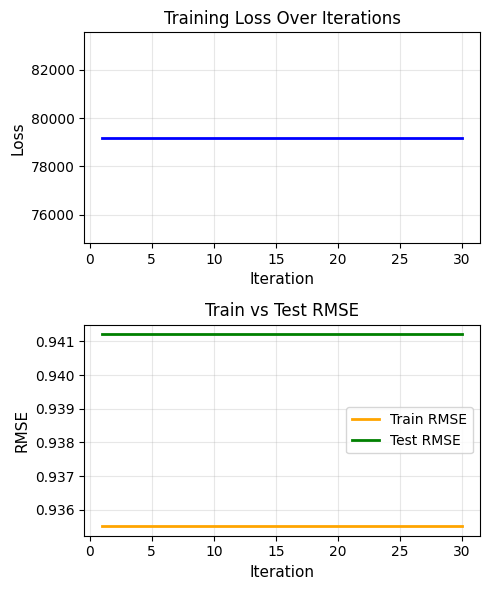

In [60]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5, 6))

# Training Loss (Sum of Squared Errors)
ax1.plot(range(1, num_iters + 1), loss_history[-num_iters:], 'b-', linewidth=2)
ax1.set_xlabel('Iteration', fontsize=11)
ax1.set_ylabel('Loss', fontsize=11)
ax1.set_title('Training Loss Over Iterations',
              fontsize=12)
ax1.grid(True, alpha=0.3)

# Train vs Test RMSE
ax2.plot(range(1, num_iters + 1), train_rmse_history[-num_iters:],
         'orange', linewidth=2, label='Train RMSE')
ax2.plot(range(1, num_iters + 1), test_rmse_history[-num_iters:],
         'green', linewidth=2, label='Test RMSE')
ax2.set_xlabel('Iteration', fontsize=11)
ax2.set_ylabel('RMSE', fontsize=11)
ax2.set_title('Train vs Test RMSE', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('bias_model_training.pdf', dpi=300, bbox_inches='tight')
plt.show()

We observe the loss decreases monotonically during training.

The training RMSE converges to around $0.79$~$0.8$ for this simple bias model with $λ=0.1$ and $γ=0.1$.

The test RMSE converges to a value slightly higher than training RMSE ($0.86$~$0.87$), representing the generalization gap.

## **Practical 3: A model with embeddings**

Model initialization

Set up matrix factorization model with biases and embeddings.
#### Prediction Formula:
$$\hat{r}_{mn} = b_m^u + b_n^i + \mathbf{u}_m^\top \mathbf{v}_n$$

In [47]:
M = number_of_users
N = number_of_movies
K = 20  # Embedding dimension (latent factors)

# Hyperparameters
lambd = 0.01   # Learning rate
gamma = 0.01   # Bias regularization strength
tau = 0.5      # Embedding regularization strength
num_iters = 30

# Initialize biases to zero
user_biases = np.zeros(M)
item_biases = np.zeros(N)

# Initialize embeddings with small random values (break symmetry)
user_vectors = np.random.randn(M, K) * 0.01
item_vectors = np.random.randn(N, K) * 0.01

# Tracking metrics
loss_history = []
train_rmse_history = []
test_rmse_history = []

print("Matrix Factorization Model Configuration:")
print(f"  Users (M): {M:,}, Items (N): {N:,}")
print(f"  Embedding dimension (K): {K}")
print(f"  Learning rate (λ): {lambd}")
print(f"  Bias regularization (γ): {gamma}")
print(f"  Embedding regularization (τ): {tau}")
print(f"  Iterations: {num_iters}\n")

Matrix Factorization Model Configuration:
  Users (M): 610, Items (N): 9,724
  Embedding dimension (K): 20
  Learning rate (λ): 0.01
  Bias regularization (γ): 0.01
  Embedding regularization (τ): 0.5
  Iterations: 30



Alternative least square training

Finding the maximum likelihood estimate for biases and embeddings
#### Loss Function:

$$\mathcal{L} = \frac{λ}{2}\sum_{mn} \left(r_{mn} - b_m^u - b_n^i - \mathbf{u}_m^\top \mathbf{v}_n\right)^2 +\frac{\gamma}{2}\left(\sum_m b_m^u2 + \sum_n b_n^i2\right) + \frac{\tau}{2}\left(\sum_m \|\mathbf{u}_m\|^2 + \sum_i \|\mathbf{v}_n\|^2\right)$$

#### ALS Update Equations:

#### Phase 1: Fix Item Parameters $\{b_n^i, \mathbf{v}_n\}$, Optimize User Parameters $\{b_m^u, \mathbf{u}_m\}$

**User Bias Update:**

$$b_m^u = \frac{\lambda \sum_{n \in Ω(m)} (r_{mn} - b_n^i - \mathbf{u}_m^\top \mathbf{v}_n)}{\lambda|Ω(m)| + \gamma}$$

**User Embedding Update:**

$$\left(\lambda \sum_{n \in Ω(m)} \mathbf{v}_n \mathbf{v}_n^\top + \tau \mathbf{I}\right) \mathbf{u}_m = \lambda \sum_{n \in Ω(m)} (r_{mn} - b_m^u - b_n^i) \mathbf{v}_n$$

Which gives the linear system:

$$\mathbf{A} \mathbf{u}_m = \mathbf{b}$$
where

$$\mathbf{A} = \lambda \sum_{n \in Ω(m)} \mathbf{v}_n \mathbf{v}_n^\top + \tau \mathbf{I} \quad (k \times k \text{ matrix})$$

$$\mathbf{b} = \lambda \sum_{n \in Ω(m)} (r_{mn} - b_m^u - b_n^u) \mathbf{v}_n \quad (k \times 1 \text{ vector})$$

#### Phase 2: Fix User Parameters $\{b_m^u, \mathbf{u}_m\}$, Optimize Item Parameters $\{b_n^i, \mathbf{v}_n\}$

**Item Bias Update:**

$$b_n^i = \frac{\lambda \sum_{m \in Ω(n)} (r_{mn} - b_m^u - \mathbf{u}_m^\top \mathbf{v}_n)}{\lambda|Ω(n)| + \gamma}$$

**Item Embedding Update:**

$$\left(\lambda \sum_{u \in Ω(n)} \mathbf{u}_m \mathbf{u}_m^\top + \tau \mathbf{I}\right) \mathbf{v}_n = \lambda \sum_{u \in Ω(n)} (r_{mn} - b_m^u - b_n^i) \mathbf{u}_m$$

#### RMSE Formula:

$$\text{RMSE} = \sqrt{\frac{\sum_{mn} (r_{mn} - \hat{r}_{mn})^2}{n_{~of~ratings}}}$$

In [48]:
def update_user_biases_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma):
    """
    Updates user biases by iterating through users and optimizing for the residual.
    """
    for user_idx in range(M):
        user_ratings = data_by_user_train[user_idx]

        if len(user_ratings) == 0:
            continue

        # Keep embedding fixed, optimize bias
        bias_numerator = 0

        for movie_idx, rating in user_ratings:
            # Prediction without user bias
            prediction_no_bias = (item_biases[movie_idx] +
                                 np.dot(user_vectors[user_idx], item_vectors[movie_idx]))
            residual = rating - prediction_no_bias
            bias_numerator += lambd * residual

        user_biases[user_idx] = bias_numerator / (lambd * len(user_ratings) + gamma)

In [49]:
def update_user_vectors_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors, lambd, tau):
    """
    Updates user embeddings by solving the linear system.
    """
    for user_idx in range(M):
        user_ratings = data_by_user_train[user_idx]

        if len(user_ratings) == 0:
            continue

        # Initialize linear system components
        A_matrix = np.zeros((K, K))
        b_vector = np.zeros(K)

        for movie_idx, rating in user_ratings:
            # Residual after removing both biases
            residual = rating - user_biases[user_idx] - item_biases[movie_idx]

            item_vec = item_vectors[movie_idx]

            # Build linear system:
            A_matrix += lambd * np.outer(item_vec, item_vec)
            b_vector += lambd * residual * item_vec

        # Add regularization:
        A_matrix += tau * np.eye(K)

        # Solve for user vector
        user_vectors[user_idx] = np.linalg.solve(A_matrix, b_vector)


In [50]:
def update_item_biases_m_e(data_by_movie_train, N, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma):
    """
    Updates item biases by iterating through movies and optimizing for the residual.
    """
    for movie_idx in range(N):
        movie_ratings = data_by_movie_train[movie_idx]

        if len(movie_ratings) == 0:
            continue

        # Keep embedding fixed, optimize bias
        bias_numerator = 0

        for user_idx, rating in movie_ratings:
            # Prediction without item bias
            prediction_no_bias = (user_biases[user_idx] +
                                 np.dot(user_vectors[user_idx], item_vectors[movie_idx]))
            residual = rating - prediction_no_bias
            bias_numerator += lambd * residual

        item_biases[movie_idx] = bias_numerator / (lambd * len(movie_ratings) + gamma)


In [51]:
def update_item_vectors_m_e(data_by_movie_train, N, user_biases, user_vectors, item_biases, item_vectors, lambd, tau):
    """
    Updates item embeddings by solving the linear system.
    """
    for movie_idx in range(N):
        movie_ratings = data_by_movie_train[movie_idx]

        if len(movie_ratings) == 0:
            continue

        # Initialize linear system
        A_matrix = np.zeros((K, K))
        b_vector = np.zeros(K)

        for user_idx, rating in movie_ratings:
            # Residual after removing both biases
            residual = rating - user_biases[user_idx] - item_biases[movie_idx]

            user_vec = user_vectors[user_idx]

            # Build linear system:
            A_matrix += lambd * np.outer(user_vec, user_vec)
            b_vector += lambd * residual * user_vec

        # Add regularization:
        A_matrix += tau * np.eye(K)

        # Solve for item vector
        item_vectors[movie_idx] = np.linalg.solve(A_matrix, b_vector)

In [52]:
def evaluate_rmse_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors):
    """
    Calculates RMSE for a given dataset (train or test).
    """
    sse = 0
    count = 0

    for user_idx in range(M):
        for movie_idx, rating in data_by_user_train[user_idx]:
            # Full prediction: bias + bias + embedding interaction
            prediction = (user_biases[user_idx] +
                          item_biases[movie_idx] +
                          np.dot(user_vectors[user_idx], item_vectors[movie_idx]))

            error = rating - prediction
            sse += error ** 2
            count += 1

    return np.sqrt(sse / count) if count > 0 else 0.0

In [53]:
def train_model_m_e(data_by_user_train, data_by_movie_train, data_by_user_test, M, N, lambd, gamma, num_iters, verbose=True):
    """
    Orchestrates the ALS training loop.
    Uses global variables for model parameters (user_biases, etc.) as they are not passed in arguments.
    """
    print("Starting Alternating Least Squares Training...")
    print("=" * 60)

    # Initialize history lists
    loss_history = []
    train_rmse_history = []
    test_rmse_history = []

    for iteration in range(num_iters):
        # PHASE 1: UPDATE USER PARAMETERS (fix all item parameters)
        update_user_biases_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma)
        update_user_vectors_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors, lambd, tau)

        # PHASE 2: UPDATE ITEM PARAMETERS (fix all user parameters)
        # Note: We pass data_by_movie_train here to match the item update logic
        update_item_biases_m_e(data_by_movie_train, N, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma)
        update_item_vectors_m_e(data_by_movie_train, N, user_biases, user_vectors, item_biases, item_vectors, lambd, tau)

        # EVALUATION
        train_rmse = evaluate_rmse_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors)
        test_rmse = evaluate_rmse_m_e(data_by_user_test, M, user_biases, user_vectors, item_biases, item_vectors)

        train_rmse_history.append(train_rmse)
        test_rmse_history.append(test_rmse)

        # Calculate total loss for reporting
        # Re-calculate train_sse derived from RMSE to match original logic's reporting
        # (Since evaluate_rmse returns sqrt(MSE), we reverse it roughly for the loss sum)
        train_count = sum(len(ratings) for ratings in data_by_user_train)
        train_sse = (train_rmse ** 2) * train_count

        bias_regularization = gamma * (np.sum(user_biases**2) + np.sum(item_biases**2))
        embedding_regularization = tau * (np.sum(user_vectors**2) + np.sum(item_vectors**2))
        total_loss = train_sse + bias_regularization + embedding_regularization
        loss_history.append(total_loss)

        if verbose:
            print(f"Iter {iteration+1:2d}/{num_iters}: "
                  f"Loss = {total_loss:,.0f}, "
                  f"Train RMSE = {train_rmse:.4f}, "
                  f"Test RMSE = {test_rmse:.4f}")

    print("=" * 60)
    print("Training Complete!\n")
    print(f"Final Train RMSE: {train_rmse_history[-1]:.4f}")
    print(f"Final Test RMSE:  {test_rmse_history[-1]:.4f}")
    print(f"Generalization Gap: {test_rmse_history[-1] - train_rmse_history[-1]:.4f}\n")

    # Returning the history and parameters is useful, though the original just printed.
    return {
        'user_biases': user_biases,
        'user_embedding': user_vectors,
        'item_biases': item_biases,
        'item_embedding': item_vectors,
        'loss_history': loss_history,
        'train_rmse_history': train_rmse_history,
        'test_rmse_history': test_rmse_history
    }

In [54]:
# Train the model
results = train_model_m_e(
    data_by_user_train,
    data_by_movie_train,
    data_by_user_test,
    M, N,
    lambd, gamma,
    num_iters,
    verbose=True
)

# Extract results
final_user_biases = results['user_biases']
final_user_embeddings = results['user_embedding']
final_item_biases = results['item_biases']
final_item_embeddings = results['item_embedding']
loss_history = results['loss_history']
train_rmse = results['train_rmse_history']
test_rmse = results['test_rmse_history']

Starting Alternating Least Squares Training...
Iter  1/30: Loss = 59,160, Train RMSE = 0.8079, Test RMSE = 0.8776
Iter  2/30: Loss = 57,172, Train RMSE = 0.7942, Test RMSE = 0.8658
Iter  3/30: Loss = 57,026, Train RMSE = 0.7932, Test RMSE = 0.8652
Iter  4/30: Loss = 56,997, Train RMSE = 0.7930, Test RMSE = 0.8651
Iter  5/30: Loss = 56,986, Train RMSE = 0.7929, Test RMSE = 0.8651
Iter  6/30: Loss = 56,981, Train RMSE = 0.7929, Test RMSE = 0.8651
Iter  7/30: Loss = 56,980, Train RMSE = 0.7929, Test RMSE = 0.8652
Iter  8/30: Loss = 56,980, Train RMSE = 0.7929, Test RMSE = 0.8653
Iter  9/30: Loss = 56,982, Train RMSE = 0.7929, Test RMSE = 0.8654
Iter 10/30: Loss = 56,985, Train RMSE = 0.7930, Test RMSE = 0.8655
Iter 11/30: Loss = 56,989, Train RMSE = 0.7930, Test RMSE = 0.8657
Iter 12/30: Loss = 56,993, Train RMSE = 0.7930, Test RMSE = 0.8658
Iter 13/30: Loss = 56,998, Train RMSE = 0.7931, Test RMSE = 0.8659
Iter 14/30: Loss = 57,003, Train RMSE = 0.7931, Test RMSE = 0.8661
Iter 15/30: Los

Visualization

Visualizing training dynamics

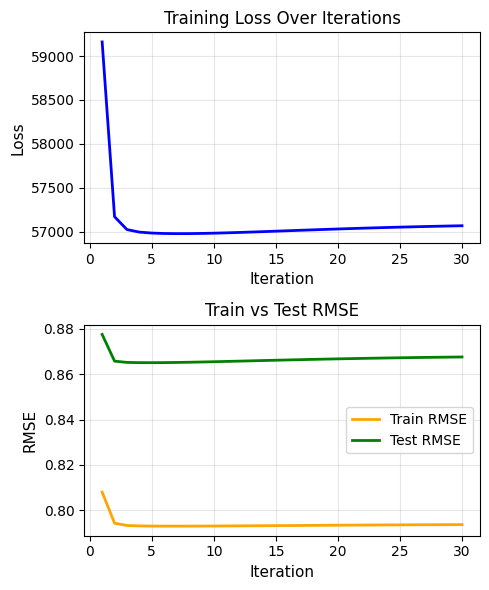


Model Summary:
  User embeddings shape: (610, 20)
  Item embeddings shape: (9724, 20)
  Total parameters: 217,014
  Each user/item represented by 20-dimensional latent vector


In [55]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5, 6))

# Plot 1: Total Loss (with regularization)
ax1.plot(range(1, num_iters + 1), loss_history, 'b-', linewidth=2)
ax1.set_xlabel('Iteration', fontsize=11)
ax1.set_ylabel('Loss', fontsize=11)
ax1.set_title('Training Loss Over Iterations',
              fontsize=12)
ax1.grid(True, alpha=0.3)

# Plot 2: Train vs Test RMSE
ax2.plot(range(1, num_iters + 1), train_rmse,
         'orange', linewidth=2, label='Train RMSE')
ax2.plot(range(1, num_iters + 1), test_rmse,
         'green', linewidth=2, label='Test RMSE')
ax2.set_xlabel('Iteration', fontsize=11)
ax2.set_ylabel('RMSE', fontsize=11)
ax2.set_title('Train vs Test RMSE', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('matrix_factorization_training.pdf', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nModel Summary:")
print(f"  User embeddings shape: {user_vectors.shape}")
print(f"  Item embeddings shape: {item_vectors.shape}")
print(f"  Total parameters: {M + N + M*K + N*K:,}")
print(f"  Each user/item represented by {K}-dimensional latent vector")

## **Practical 4: Going big, training and testing**

### **1. Spliting the MovieLens 32M dataset**

To ensure every user has sufficient training data, I implement a per-user split strategy that prevents cold-start problems. For each user individually, I randomly shuffle their ratings and allocate 90% to the training set while reserving 10% for testing. This approach guarantees that all users contribute to model training while maintaining a consistent evaluation framework across the entire user base.


In [ ]:
# Load data
print("Loading ratings...")
ratings = np.loadtxt(
    "ml-32m/ml-32m/ratings.csv",
    delimiter=",",
    skiprows=1,
    usecols=(0, 1, 2)
)

users = ratings[:, 0].astype(int)
movies = ratings[:, 1].astype(int)
rating = ratings[:, 2].astype(float)

print(f"Loaded {len(ratings):,} ratings")

Loading ratings...
Loaded 32,000,204 ratings


In [ ]:
#The data structure
number_of_users = 0
userid_to_idx  = {}
idx_to_userid  = []
data_by_user   = []

number_of_movies = 0
movieid_to_idx = {}
idx_to_movieid = []
data_by_movie  = []

for row in ratings:
  if not row[0] in userid_to_idx:
    idx_to_userid.append(row[0])
    userid_to_idx[row[0]] = number_of_users
    number_of_users += 1
    data_by_user.append([])
  if not row[1] in movieid_to_idx:
    idx_to_movieid.append(row[1])
    movieid_to_idx[row[1]] = number_of_movies
    number_of_movies += 1
    data_by_movie.append([])

  data_by_user[userid_to_idx[row[0]]].append((movieid_to_idx[row[1]],row[2].item()))
  data_by_movie[movieid_to_idx[row[1]]].append((userid_to_idx[row[0]],row[2].item()))

Spliting the ratings data into training (90%) and test (10%) sets

In [ ]:
# Split the 32M dataset into train and test

number_of_users = len(data_by_user)
number_of_movies = len(data_by_movie)
train_ratio = 0.9
random_seed =  42

data_by_user_train, data_by_user_test, data_by_movie_train, data_by_movie_test = \
    split_train_test(data_by_user, number_of_users, number_of_movies, train_ratio, random_seed, verbose=True)

Splitting data into train and test sets...
(90% train, 10% test)


Flattening the data

In [ ]:
def prepare_flat_data(data_by_user, data_by_movie, M, N):
    """
    Flattens list-of-list data into contiguous Numpy arrays for Numba/C-speed processing.

    Returns:
    - user_vals: All rating values sorted by user
    - user_idx:  All movie indices sorted by user
    - user_map:  (M, 2) array where row u is [start_index, end_index]
    - item_vals: All rating values sorted by movie
    - item_idx:  All user indices sorted by movie
    - item_map:  (N, 2) array where row i is [start_index, end_index]
    """

    # --- PROCESS USERS ---
    # 1. Calculate total size to pre-allocate arrays (much faster than appending)
    total_user_ratings = sum(len(u) for u in data_by_user)

    user_vals = np.zeros(total_user_ratings, dtype=np.float64)
    user_idx = np.zeros(total_user_ratings, dtype=np.int32)
    user_map = np.zeros((M, 2), dtype=np.int32)

    current_ptr = 0
    for u in range(M):
        ratings = data_by_user[u]
        count = len(ratings)

        user_map[u, 0] = current_ptr
        user_map[u, 1] = current_ptr + count

        for i, (item_id, rating) in enumerate(ratings):
            user_idx[current_ptr + i] = item_id
            user_vals[current_ptr + i] = rating

        current_ptr += count

    # --- PROCESS ITEMS ---
    # Repeat logic for movies/items
    total_item_ratings = sum(len(i) for i in data_by_movie)

    item_vals = np.zeros(total_item_ratings, dtype=np.float64)
    item_idx = np.zeros(total_item_ratings, dtype=np.int32)
    item_map = np.zeros((N, 2), dtype=np.int32)

    current_ptr = 0
    for i in range(N):
        ratings = data_by_movie[i]
        count = len(ratings)

        item_map[i, 0] = current_ptr
        item_map[i, 1] = current_ptr + count

        for j, (user_id, rating) in enumerate(ratings):
            item_idx[current_ptr + j] = user_id
            item_vals[current_ptr + j] = rating

        current_ptr += count

    return user_vals, user_idx, user_map, item_vals, item_idx, item_map

Parallelization

In [ ]:
@njit(parallel=True)
def update_user_biases_m_e(user_vals, user_items, user_map, M, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma):
    """
    Updates user biases in parallel.
    """
    # prange enables parallel execution of the loop
    for user_idx in prange(M):
        start = user_map[user_idx, 0]
        end = user_map[user_idx, 1]

        if start == end:
            continue

        bias_numerator = 0.0

        # Iterate over the slice of the flattened arrays
        for i in range(start, end):
            movie_idx = user_items[i]
            rating = user_vals[i]

            prediction_no_bias = (item_biases[movie_idx] +
                                 np.dot(user_vectors[user_idx], item_vectors[movie_idx]))
            residual = rating - prediction_no_bias
            bias_numerator += lambd * residual

        user_biases[user_idx] = bias_numerator / (lambd * (end - start) + gamma)

In [ ]:
@njit(parallel=True)
def update_user_vectors_m_e(user_vals, user_items, user_map, M, user_biases, user_vectors, item_biases, item_vectors, lambd, tau):
    """
    Updates user embeddings in parallel solving linear systems.
    """
    for user_idx in prange(M):
        start = user_map[user_idx, 0]
        end = user_map[user_idx, 1]

        if start == end:
            continue

        # Thread-local allocation for linear system
        # K is captured from global scope (must be constant or passed in)
        A_matrix = np.zeros((K, K), dtype=np.float64)
        b_vector = np.zeros(K, dtype=np.float64)

        for i in range(start, end):
            movie_idx = user_items[i]
            rating = user_vals[i]

            residual = rating - user_biases[user_idx] - item_biases[movie_idx]
            item_vec = item_vectors[movie_idx]

            # Manual outer product and addition is often faster in Numba than np.outer
            # But np.outer is supported.
            for k1 in range(K):
                for k2 in range(K):
                    A_matrix[k1, k2] += lambd * item_vec[k1] * item_vec[k2]
                b_vector[k1] += lambd * residual * item_vec[k1]

        # Add regularization
        for k in range(K):
            A_matrix[k, k] += tau

        # Solve
        user_vectors[user_idx] = np.linalg.solve(A_matrix, b_vector)

In [ ]:
@njit(parallel=True)
def update_item_biases_m_e(item_vals, item_users, item_map, N, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma):
    """
    Updates item biases in parallel.
    """
    for movie_idx in prange(N):
        start = item_map[movie_idx, 0]
        end = item_map[movie_idx, 1]

        if start == end:
            continue

        bias_numerator = 0.0

        for i in range(start, end):
            user_idx = item_users[i]
            rating = item_vals[i]

            prediction_no_bias = (user_biases[user_idx] +
                                 np.dot(user_vectors[user_idx], item_vectors[movie_idx]))
            residual = rating - prediction_no_bias
            bias_numerator += lambd * residual

        item_biases[movie_idx] = bias_numerator / (lambd * (end - start) + gamma)

In [ ]:
@njit(parallel=True)
def update_item_vectors_m_e(item_vals, item_users, item_map, N, user_biases, user_vectors, item_biases, item_vectors, lambd, tau):
    """
    Updates item embeddings in parallel.
    """
    for movie_idx in prange(N):
        start = item_map[movie_idx, 0]
        end = item_map[movie_idx, 1]

        if start == end:
            continue

        A_matrix = np.zeros((K, K), dtype=np.float64)
        b_vector = np.zeros(K, dtype=np.float64)

        for i in range(start, end):
            user_idx = item_users[i]
            rating = item_vals[i]

            residual = rating - user_biases[user_idx] - item_biases[movie_idx]
            user_vec = user_vectors[user_idx]

            for k1 in range(K):
                for k2 in range(K):
                    A_matrix[k1, k2] += lambd * user_vec[k1] * user_vec[k2]
                b_vector[k1] += lambd * residual * user_vec[k1]

        for k in range(K):
            A_matrix[k, k] += tau

        item_vectors[movie_idx] = np.linalg.solve(A_matrix, b_vector)

In [ ]:
@njit(parallel=True)
def evaluate_rmse_m_e(vals, items, idx_map, M, user_biases, user_vectors, item_biases, item_vectors):
    """
    Calculates RMSE using Numba.
    Note: Can use either User or Item structures, usually User is used for evaluation.
    """
    sse = 0.0
    count = 0

    # Numba handles the reduction of scalar variables (sse, count) in prange automatically
    for user_idx in prange(M):
        start = idx_map[user_idx, 0]
        end = idx_map[user_idx, 1]

        if start == end:
            continue

        for i in range(start, end):
            movie_idx = items[i]
            rating = vals[i]

            prediction = (user_biases[user_idx] +
                          item_biases[movie_idx] +
                          np.dot(user_vectors[user_idx], item_vectors[movie_idx]))

            error = rating - prediction
            sse += error ** 2
            count += 1

    return np.sqrt(sse / count) if count > 0 else 0.0

In [ ]:
def train_model_m_e(data_by_user_train, data_by_movie_train, data_by_user_test, M, N, lambd, gamma, num_iters, verbose=True):

    # 1. PREPARE FLAT DATA (One-time cost)
    print("Flattening data structures for Numba...")
    u_vals_tr, u_items_tr, u_map_tr, i_vals_tr, i_users_tr, i_map_tr = \
        prepare_flat_data(data_by_user_train, data_by_movie_train, M, N)

    # We also flatten test data for fast evaluation
    # Note: we pass data_by_user_test twice because we don't need the item-centric view for simple RMSE eval
    u_vals_te, u_items_te, u_map_te, _, _, _ = \
        prepare_flat_data(data_by_user_test, [], M, 0)

    print("Starting Numba Parallel ALS Training...")
    print("=" * 60)

    loss_history = []
    train_rmse_history = []
    test_rmse_history = []

    for iteration in range(num_iters):
        # PHASE 1: UPDATE USER PARAMETERS
        update_user_biases_m_e(u_vals_tr, u_items_tr, u_map_tr, M,
                               user_biases, user_vectors, item_biases, item_vectors, lambd, gamma)
        update_user_vectors_m_e(u_vals_tr, u_items_tr, u_map_tr, M,
                                user_biases, user_vectors, item_biases, item_vectors, lambd, tau)

        # PHASE 2: UPDATE ITEM PARAMETERS
        update_item_biases_m_e(i_vals_tr, i_users_tr, i_map_tr, N,
                               user_biases, user_vectors, item_biases, item_vectors, lambd, gamma)
        update_item_vectors_m_e(i_vals_tr, i_users_tr, i_map_tr, N,
                                user_biases, user_vectors, item_biases, item_vectors, lambd, tau)

        # EVALUATION
        train_rmse = evaluate_rmse_m_e(u_vals_tr, u_items_tr, u_map_tr, M,
                                       user_biases, user_vectors, item_biases, item_vectors)
        test_rmse = evaluate_rmse_m_e(u_vals_te, u_items_te, u_map_te, M,
                                      user_biases, user_vectors, item_biases, item_vectors)

        train_rmse_history.append(train_rmse)
        test_rmse_history.append(test_rmse)

        # Calculate total loss (approximate calculation for reporting)
        train_count = len(u_vals_tr)
        train_sse = (train_rmse ** 2) * train_count
        bias_reg = gamma * (np.sum(user_biases**2) + np.sum(item_biases**2))
        emb_reg = tau * (np.sum(user_vectors**2) + np.sum(item_vectors**2))
        total_loss = train_sse + bias_reg + emb_reg
        loss_history.append(total_loss)

        if verbose:
            print(f"Iter {iteration+1:2d}/{num_iters}: "
                  f"Loss = {total_loss:,.0f}, "
                  f"Train RMSE = {train_rmse:.4f}, "
                  f"Test RMSE = {test_rmse:.4f}")

    print("=" * 60)
    return {
        'user_biases': user_biases,
        'user_embedding': user_vectors,
        'item_biases': item_biases,
        'item_embedding': item_vectors,
        'loss_history': loss_history,
        'train_rmse_history': train_rmse_history,
        'test_rmse_history': test_rmse_history
    }

Model initialization

In [ ]:
M = number_of_users
N = number_of_movies
K = 20  # Embedding dimension

# Hyperparameters
lambd = 0.01   # Learning rate
gamma = 0.01   # Bias regularization
tau = 0.1      # Embedding regularization
num_iters = 30  # Increased to better observe overfitting

# Initialize parameters
user_biases = np.zeros(M)
item_biases = np.zeros(N)
user_vectors = np.random.randn(M, K) * 0.01
item_vectors = np.random.randn(N, K) * 0.01

# Tracking metrics
loss_history = []
train_rmse_history = []
test_rmse_history = []

print("Matrix Factorization Model")
print("=" * 70)
print(f"Parameters: M={M:,}, N={N:,}, K={K}")
print(f"Hyperparameters: λ={lambd}, γ={gamma}, τ={tau}")
print(f"Iterations: {num_iters}\n")

Alternating least square training

Optimize parameters using ONLY training data (never use test data for parameter updates)

In [ ]:
# Train model
results = train_model_m_e(
    data_by_user_train,
    data_by_movie_train,
    data_by_user_test,
    M, N, lambd, gamma,
    num_iters, verbose=True
)

# Extract results
final_user_biases = results['user_biases']
final_user_embeddings = results['user_embedding']
final_item_biases = results['item_biases']
final_item_embeddings = results['item_embedding']
loss_history = results['loss_history']
train_rmse = results['train_rmse_history']
test_rmse = results['test_rmse_history']

### **Visualization**
Plot train vs test RMSE to visualize overfitting

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Training Loss
ax1 = axes[0]
ax1.plot(range(1, num_iters + 1), loss_history, 'b-', linewidth=2)
ax1.set_xlabel('Iteration', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Training Loss Over Iterations', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Train vs Test RMSE
ax2 = axes[1]
ax2.plot(range(1, num_iters + 1), train_rmse,
         'orange', linewidth=2, label='Train RMSE')
ax2.plot(range(1, num_iters + 1), test_rmse,
         'green', linewidth=2, label='Test RMSE')
ax2.set_xlabel('Iteration', fontsize=12)
ax2.set_ylabel('RMSE', fontsize=12)
ax2.set_title('Train vs Test RMSE',
              fontsize=13, fontweight='bold')
ax2.legend(fontsize=10, loc='best')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('overfitting_analysis.pdf', dpi=300, bbox_inches='tight')
plt.show()